# Candidates Analysis — Data Engineer Code Challenge

This notebook reads **exclusively from the relational database** produced by
`etl.py` (`db/candidates.db`) — never from the original CSV — and builds the
four required visualizations:

1. Hires by technology (horizontal bar chart)
2. Hires by year (vertical bar chart)
3. Hires by seniority (treemap)
4. Hires by country over the years — USA, Brazil, Colombia, Ecuador (multiline chart)

A candidate is considered **hired** when both `Code Challenge Score >= 7`
and `Technical Interview Score >= 7` (see `etl.py::HIRE_THRESHOLD`).

> Run `python etl.py` from the project root before running this notebook,
> so `db/candidates.db` exists and is up to date.


In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import squarify

DB_PATH = Path("..") / "db" / "candidates.db"
if not DB_PATH.exists():
    DB_PATH = Path("db") / "candidates.db"  # fallback if run from project root

assert DB_PATH.exists(), f"Database not found at {DB_PATH}. Run `python etl.py` first."

conn = sqlite3.connect(DB_PATH)
print(f"Connected to {DB_PATH}")


Connected to ../db/candidates.db


In [2]:
# --- Shared style: validated categorical / sequential palette -------------
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "text.color": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "font.family": "sans-serif",
    "font.size": 11,
})

CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
               "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQUENTIAL_BLUE = "#2a78d6"


def style_axes(ax, show_x_grid=False, show_y_grid=True):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.xaxis.grid(show_x_grid)
    ax.yaxis.grid(show_y_grid)
    ax.set_axisbelow(True)


## 1. Hires by Technology (horizontal bar chart)

In [3]:
query_tech = '''
SELECT t.technology_name AS technology, COUNT(*) AS hires
FROM candidates c
JOIN dim_technology t ON c.technology_id = t.technology_id
WHERE c.is_hired = 1
GROUP BY t.technology_name
ORDER BY hires DESC
'''
df_tech = pd.read_sql_query(query_tech, conn)
df_tech


,technology,hires
0,Game Development,519
1,DevOps,495
2,System Administration,293
3,Development - CMS Backend,284
4,Database Administration,282
5,Adobe Experience Manager,282
6,Client Success,271
7,Security,266
8,Development - Frontend,266
9,Mulesoft,260


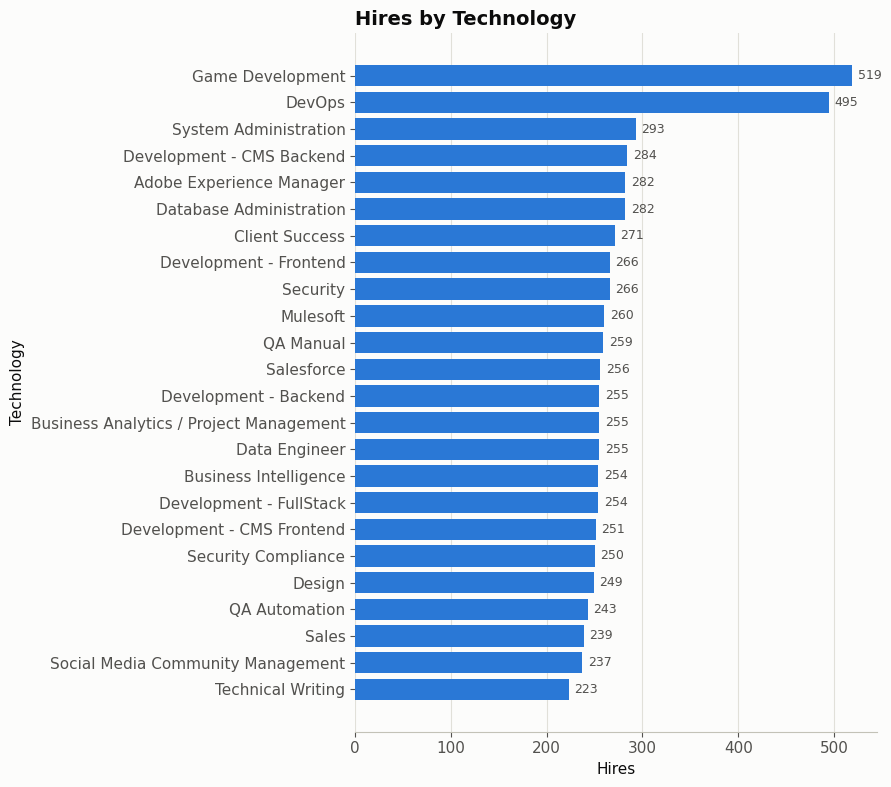

In [4]:
# Sorted ascending here so the largest bar ends up on top when plotted
# with barh (matplotlib draws the first row at the bottom of the axis).
df_tech_sorted = df_tech.sort_values("hires", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 8))
bars = ax.barh(df_tech_sorted["technology"], df_tech_sorted["hires"], color=SEQUENTIAL_BLUE)
ax.bar_label(bars, padding=4, color="#52514e", fontsize=9)
ax.set_xlabel("Hires")
ax.set_ylabel("Technology")
ax.set_title("Hires by Technology", fontsize=14, fontweight="bold", loc="left")
style_axes(ax, show_x_grid=True, show_y_grid=False)
plt.tight_layout()
plt.savefig("hires_by_technology.png", dpi=150, bbox_inches="tight")
plt.show()


## 2. Hires by Year (vertical bar chart)

In [5]:
query_year = '''
SELECT application_year AS year, COUNT(*) AS hires
FROM candidates
WHERE is_hired = 1
GROUP BY application_year
ORDER BY application_year
'''
df_year = pd.read_sql_query(query_year, conn)
df_year


,year,hires
0,2018,1409
1,2019,1524
2,2020,1485
3,2021,1485
4,2022,795


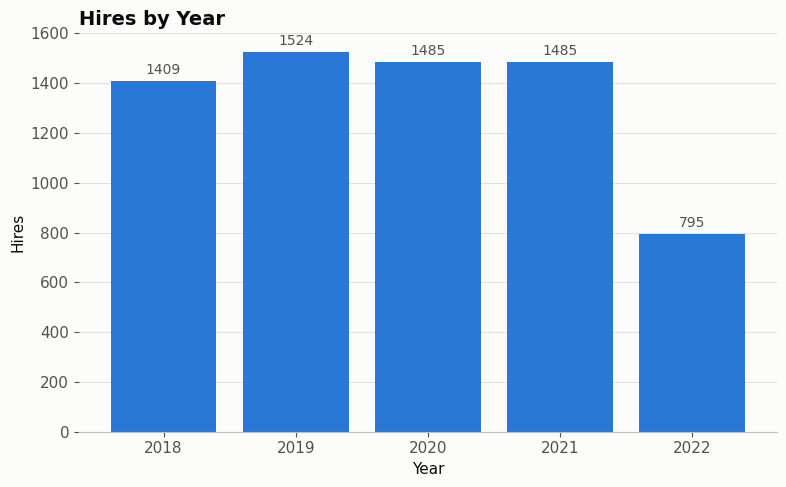

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(df_year["year"].astype(str), df_year["hires"], color=SEQUENTIAL_BLUE)
ax.bar_label(bars, padding=3, color="#52514e", fontsize=10)
ax.set_xlabel("Year")
ax.set_ylabel("Hires")
ax.set_title("Hires by Year", fontsize=14, fontweight="bold", loc="left")
style_axes(ax, show_x_grid=False, show_y_grid=True)
plt.tight_layout()
plt.savefig("hires_by_year.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Hires by Seniority (treemap)

In [7]:
query_seniority = '''
SELECT s.seniority_name AS seniority, COUNT(*) AS hires
FROM candidates c
JOIN dim_seniority s ON c.seniority_id = s.seniority_id
WHERE c.is_hired = 1
GROUP BY s.seniority_name, s.seniority_rank
ORDER BY s.seniority_rank
'''
df_seniority = pd.read_sql_query(query_seniority, conn)
df_seniority


,seniority,hires
0,Trainee,973
1,Intern,985
2,Junior,977
3,Mid-Level,924
4,Senior,939
5,Lead,929
6,Architect,971


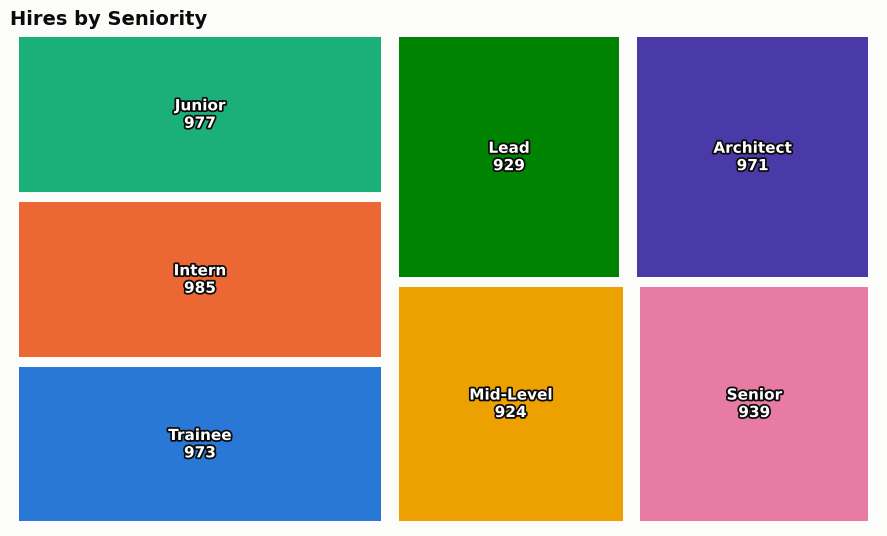

In [8]:
import matplotlib.patheffects as pe

# Kept in seniority_rank order (Trainee -> Architect) so each level gets a
# fixed, stable color from the categorical palette rather than one picked
# by size; labels carry both the name and the count since a treemap has no
# axis to read values off of.
labels = [f"{row.seniority}\n{row.hires}" for row in df_seniority.itertuples()]
colors = CATEGORICAL[: len(df_seniority)]

fig, ax = plt.subplots(figsize=(9, 5.5))
squarify.plot(
    sizes=df_seniority["hires"],
    label=labels,
    color=colors,
    pad=True,
    ax=ax,
    text_kwargs={
        "fontsize": 11,
        "fontweight": "bold",
        "color": "white",
        "path_effects": [pe.withStroke(linewidth=2.5, foreground="#0b0b0b")],
    },
)
ax.set_title("Hires by Seniority", fontsize=14, fontweight="bold", loc="left")
ax.axis("off")
plt.tight_layout()
plt.savefig("hires_by_seniority.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Hires by Country Over the Years (multiline chart)

Limited to USA, Brazil, Colombia and Ecuador, as required.


In [9]:
COUNTRIES = ["United States of America", "Brazil", "Colombia", "Ecuador"]
placeholders = ",".join("?" for _ in COUNTRIES)
query_country = f'''
SELECT co.country_name AS country, c.application_year AS year, COUNT(*) AS hires
FROM candidates c
JOIN dim_country co ON c.country_id = co.country_id
WHERE c.is_hired = 1 AND co.country_name IN ({placeholders})
GROUP BY co.country_name, c.application_year
ORDER BY c.application_year, co.country_name
'''
df_country = pd.read_sql_query(query_country, conn, params=COUNTRIES)

# Fill in any (country, year) combos with zero hires so lines don't skip gaps.
all_years = range(df_country["year"].min(), df_country["year"].max() + 1)
full_index = pd.MultiIndex.from_product([COUNTRIES, all_years], names=["country", "year"])
df_country_full = (
    df_country.set_index(["country", "year"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)
df_country_full.pivot(index="year", columns="country", values="hires")


country,Brazil,Colombia,Ecuador,United States of America
year,,,,
2018,9,7,1,5
2019,7,8,3,3
2020,6,8,8,4
2021,7,1,5,8
2022,4,1,3,5


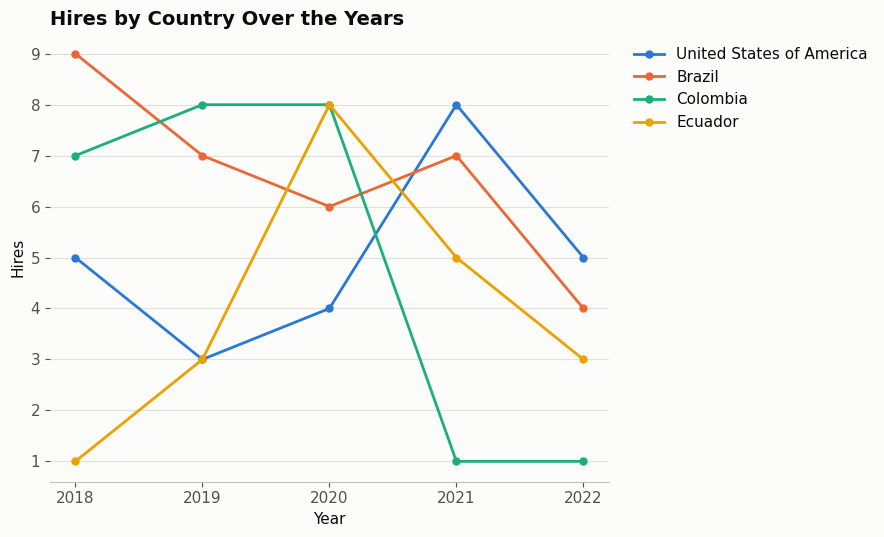

In [10]:
pivot = df_country_full.pivot(index="year", columns="country", values="hires")[COUNTRIES]

fig, ax = plt.subplots(figsize=(9, 5.5))
for color, country in zip(CATEGORICAL, COUNTRIES):
    ax.plot(
        pivot.index, pivot[country],
        marker="o", markersize=5, linewidth=2,
        color=color, label=country,
    )
ax.set_xlabel("Year")
ax.set_ylabel("Hires")
ax.set_title("Hires by Country Over the Years", fontsize=14, fontweight="bold", loc="left")
ax.set_xticks(list(pivot.index))
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1.0))
style_axes(ax, show_x_grid=False, show_y_grid=True)
plt.tight_layout()
plt.savefig("hires_by_country_over_years.png", dpi=150, bbox_inches="tight")
plt.show()


## Wrap-up

In [11]:
conn.close()
print("Done. Charts saved as PNG files alongside this notebook.")


Done. Charts saved as PNG files alongside this notebook.
